<a href="https://colab.research.google.com/github/rafiebazine/rag-image-captioning/blob/hadil/phase_02_preprocessing/01_caption_cleaning_and_diversity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/rafiebazine/rag-image-captioning.git
%cd rag-image-captioning
!git checkout hadil
!git merge origin/main

Cloning into 'rag-image-captioning'...
remote: Enumerating objects: 158, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 158 (delta 7), reused 4 (delta 2), pack-reused 133 (from 1)
Receiving objects: 100% (158/158), 1.15 MiB | 7.87 MiB/s, done.
Resolving deltas: 100% (65/65), done.
/content/rag-image-captioning
branch 'hadil' set up to track 'origin/hadil'.
Switched to a new branch 'hadil'
Already up to date.


In [2]:
import json, re, os
from collections import Counter

SPLIT_DIR = "phase_01_data_exploration/splitted_data_set"
OUT_DIR = "phase_02_preprocessing/processed"
os.makedirs(OUT_DIR, exist_ok=True)

splits = {}
for name in ["kb_10k", "val_100", "test_100", "test_1000"]:
    with open(f"{SPLIT_DIR}/{name}.json") as f:
        splits[name] = json.load(f)
    print(name, len(splits[name]))

kb_10k 10000
val_100 100
test_100 100
test_1000 1000


In [3]:
def clean_caption(text):
    text = text.strip().lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)   # remove punctuation
    text = re.sub(r"\s+", " ", text).strip()    # normalise whitespace
    return text

for name, data in splits.items():
    out = []
    for item in data:
        new = {k: v for k, v in item.items() if k != "captions"}
        new["captions_raw"] = item["captions"]                     # unchanged, for evaluation
        new["captions_clean"] = [clean_caption(c) for c in item["captions"]]
        out.append(new)
    with open(f"{OUT_DIR}/{name}_clean.json", "w") as f:
        json.dump(out, f, ensure_ascii=False)
    print("saved", name)

saved kb_10k
saved val_100
saved test_100
saved test_1000


In [4]:
for name in splits:
    data = json.load(open(f"{OUT_DIR}/{name}_clean.json"))
    assert all(len(x["captions_raw"]) == 5 == len(x["captions_clean"]) for x in data)
    assert all(c for x in data for c in x["captions_clean"]), "empty caption after cleaning"
    ids = [x["image_id"] for x in data]
    assert len(ids) == len(set(ids)), "duplicate IDs"
print("OK")

kb = json.load(open(f"{OUT_DIR}/kb_10k_clean.json"))
print(kb[0]["captions_raw"][3], "->", kb[0]["captions_clean"][3])

OK
A bicycle figurine in which the front wheel is replaced with a clock
 -> a bicycle figurine in which the front wheel is replaced with a clock


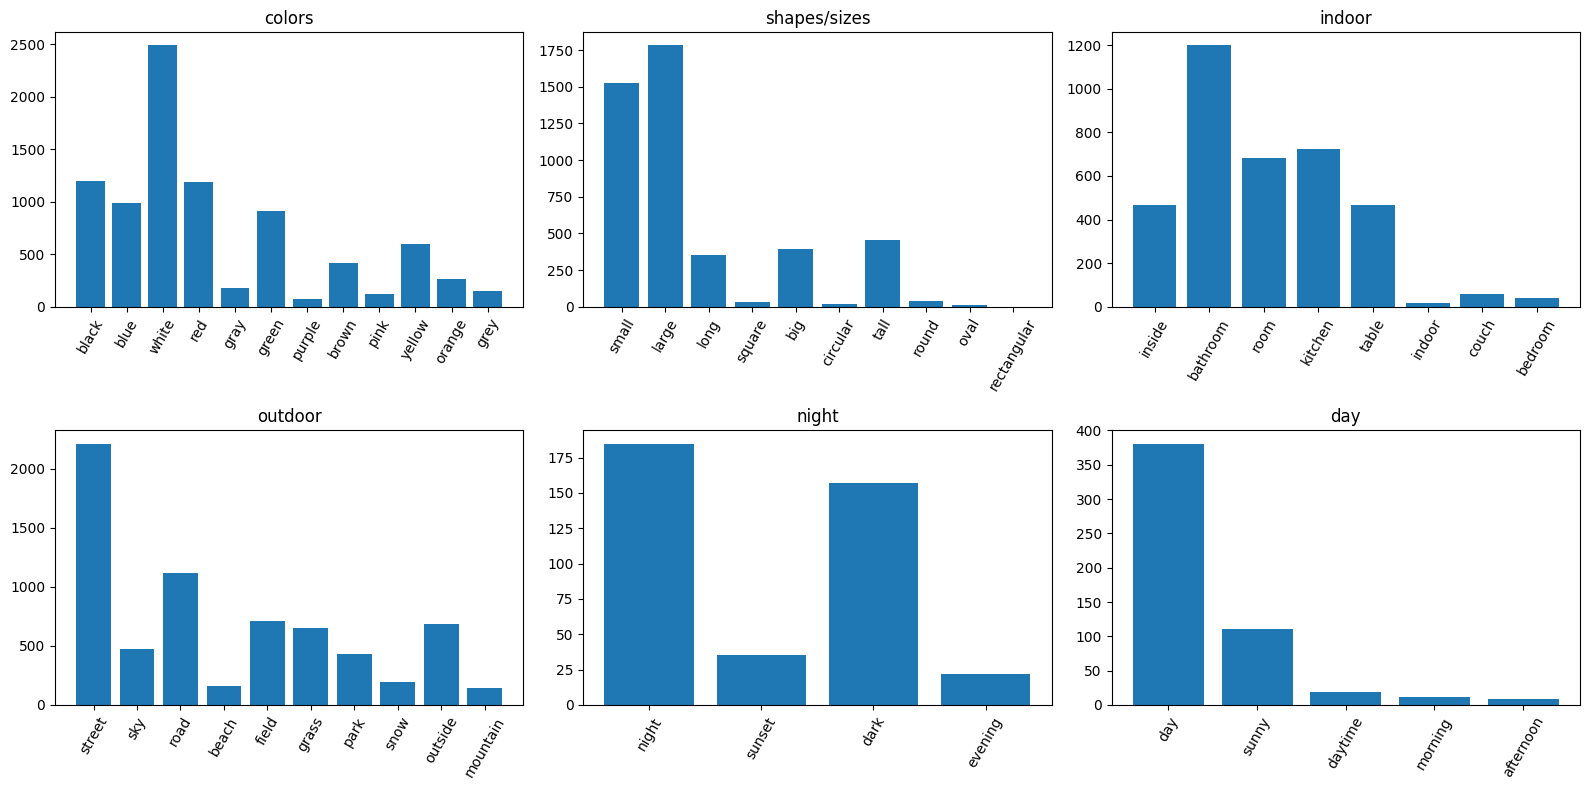

In [5]:
import matplotlib.pyplot as plt

kb_caps = [" ".join(x["captions_clean"]).split() for x in kb]  # words per image

groups = {
  "colors":  ["red","blue","green","yellow","black","white","brown","orange","pink","purple","gray","grey"],
  "shapes/sizes": ["round","square","rectangular","circular","oval","long","tall","large","small","big"],
  "indoor":  ["kitchen","bathroom","bedroom","room","inside","indoor","couch","table"],
  "outdoor": ["street","park","beach","field","outside","road","grass","snow","mountain","sky"],
  "night":   ["night","dark","evening","sunset"],
  "day":     ["sunny","daytime","day","morning","afternoon"],
}

counts = {g: Counter() for g in groups}
for words in kb_caps:
    s = set(words)
    for g, kws in groups.items():
        for w in kws:
            if w in s:
                counts[g][w] += 1

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (g, c) in zip(axes.flat, counts.items()):
    ax.bar(c.keys(), c.values()); ax.set_title(g); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/diversity_analysis.png", dpi=150); plt.show()